
<div style="padding:32px;border-radius:18px;background:linear-gradient(125deg,#071426,#102d46,#155e75);color:#f8fafc;border:1px solid #38bdf8;">
<h1 style="font-size:34px;">LinkedIn Job Market Intelligence</h1>
<h3 style="color:#67e8f9;">Exploratory Analysis of 124K+ Job Postings · 2023–2024</h3>
<p>A comprehensive exploration of job demand, compensation, work arrangements, experience levels, locations, skills, benefits, employers, and hiring activity.</p>
<p><b>Author:</b> Mobeen Fatima · <span style="color:#67e8f9;">@mobeenfatimah</span></p>
</div>

### Research objectives
- Understand the structure and quality of the job-posting data.
- Explore titles, work types, experience levels, locations, and application activity.
- Analyze compensation without mixing currencies or pay periods.
- Identify commonly requested skills, industries, and benefits.
- Connect job postings with company attributes.
- Apply lightweight NLP and a baseline salary-band classifier where data coverage permits.

> **Caution:** This is a scraped sample, not a complete census of vacancies. Missing salary values are not zero. Hourly, monthly, and yearly compensation must not be compared as equivalent units. Observational patterns do not prove causation.


## 1. Import libraries

Load lightweight libraries for data analysis, visualization, and notebook display.

In [1]:
import os, glob, warnings, re
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
print("Libraries imported.")

Libraries imported.


## 2. Configure visualization style

Use a consistent navy, cyan, and teal palette for readable Kaggle-safe charts.

In [2]:
plt.rcParams.update({"figure.figsize":(11,5.5),"figure.dpi":110,"axes.titlesize":15,
"axes.titleweight":"bold","axes.spines.top":False,"axes.spines.right":False,
"axes.grid":True,"grid.alpha":0.22,"font.size":10})
NAVY,CYAN,TEAL="#12304A","#38BDF8","#0F9D9A"
ORANGE,RED,GREEN="#F59E0B","#E76F51","#2A9D8F"
print("Plot style configured.")

Plot style configured.


## 3. Set reproducibility options

Set a fixed seed and convenient Pandas display settings.

In [3]:
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns",80)
pd.set_option("display.max_colwidth",100)
pd.set_option("display.float_format",lambda x:f"{x:,.2f}")
print("Seed:",RANDOM_STATE)

Seed: 42


## 4. Discover dataset files

Search Kaggle input mounts and the current directory for the dataset CSV files.

In [4]:
roots=["/kaggle/input",".","/kaggle/working"]
csv_paths=[]
for root in roots:
    if os.path.isdir(root):
        csv_paths += glob.glob(os.path.join(root,"**","*.csv"),recursive=True)
csv_paths=sorted(set(csv_paths))
print("CSV files found:",len(csv_paths))
for p in csv_paths[:30]: print(p)

CSV files found: 11
/kaggle/input/datasets/arshkon/linkedin-job-postings/companies/companies.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/companies/company_industries.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/companies/company_specialities.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/companies/employee_counts.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/jobs/benefits.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/jobs/job_industries.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/jobs/job_skills.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/jobs/salaries.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/mappings/industries.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/mappings/skills.csv
/kaggle/input/datasets/arshkon/linkedin-job-postings/postings.csv


## 5. Create a filename lookup

Build a reusable mapping from CSV filename to its full path.

In [5]:
file_lookup={}
for p in csv_paths:
    file_lookup.setdefault(os.path.basename(p).lower(),[]).append(p)
for f in ["postings.csv","companies.csv","employee_counts.csv","benefits.csv",
          "job_skills.csv","job_industries.csv","industries.csv","skills.csv"]:
    print(f, "FOUND" if f in file_lookup else "not found")

postings.csv FOUND
companies.csv FOUND
employee_counts.csv FOUND
benefits.csv FOUND
job_skills.csv FOUND
job_industries.csv FOUND
industries.csv FOUND
skills.csv FOUND


## 6. Load job postings

Load the central postings table. This is the primary table for most analyses.

In [6]:
if "postings.csv" not in file_lookup:
    raise FileNotFoundError("Attach the LinkedIn Job Postings dataset; postings.csv was not found.")
postings=pd.read_csv(file_lookup["postings.csv"][0],low_memory=False)
print("Shape:",postings.shape)
display(postings.head(3))

Shape: (123849, 31)


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,min_salary,formatted_work_type,applies,original_listed_time,remote_allowed,job_posting_url,application_url,application_type,expiry,closed_time,formatted_experience_level,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in New Jersey is seeking an administrative Marketing C...,20.00,HOURLY,"Princeton, NJ","2,774,458.00",20.00,NaN,17.00,Full-time,2.00,"1,713,397,508,000.00",NaN,https://www.linkedin.com/jobs/view/921716/?trk=jobs_biz_prem_srch,NaN,ComplexOnsiteApply,"1,715,989,508,000.00",NaN,NaN,Requirements: \n\nWe are seeking a College or Graduate Student (can also be completed with schoo...,"1,713,397,508,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"38,480.00","8,540.00","34,021.00"
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committed to serving clients with best practices to help ...",50.00,HOURLY,"Fort Collins, CO",NaN,1.00,NaN,30.00,Full-time,NaN,"1,712,857,887,000.00",NaN,https://www.linkedin.com/jobs/view/1829192/?trk=jobs_biz_prem_srch,NaN,ComplexOnsiteApply,"1,715,449,887,000.00",NaN,NaN,NaN,"1,712,857,887,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"83,200.00","80,521.00","8,069.00"
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting applications for an Assistant Restaurant Manager.\nWe offer h...,"65,000.00",YEARLY,"Cincinnati, OH","64,896,719.00",8.00,NaN,"45,000.00",Full-time,NaN,"1,713,277,614,000.00",NaN,https://www.linkedin.com/jobs/view/10998357/?trk=jobs_biz_prem_srch,NaN,ComplexOnsiteApply,"1,715,869,614,000.00",NaN,NaN,We are currently accepting resumes for FOH - Asisstant Restaurant Management with a strong focus...,"1,713,277,614,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"55,000.00","45,202.00","39,061.00"


## 7. Load supporting tables

Load company, employee, benefit, skill, industry, and mapping tables when present.

In [7]:
def load_optional(name):
    paths=file_lookup.get(name.lower(),[])
    return pd.read_csv(paths[0],low_memory=False) if paths else None
companies=load_optional("companies.csv")
employee_counts=load_optional("employee_counts.csv")
benefits=load_optional("benefits.csv")
job_skills=load_optional("job_skills.csv")
job_industries=load_optional("job_industries.csv")
industries=load_optional("industries.csv")
skills=load_optional("skills.csv")
for n,x in [("companies",companies),("employee_counts",employee_counts),("benefits",benefits),
            ("job_skills",job_skills),("job_industries",job_industries),("industries",industries),("skills",skills)]:
    print(n,None if x is None else x.shape)

companies (24473, 10)
employee_counts (35787, 4)
benefits (67943, 3)
job_skills (213768, 2)
job_industries (164808, 2)
industries (422, 2)
skills (35, 2)


## 8. Inspect columns and types

Review the schema, dtypes, and missingness before cleaning.

In [8]:
print("Columns:",len(postings.columns))
display(pd.DataFrame({"column":postings.columns,"dtype":postings.dtypes.astype(str).values,
"missing":postings.isna().sum().values,
"missing_pct":(postings.isna().mean().values*100).round(1)}).sort_values("missing_pct",ascending=False))

Columns: 31


,column,dtype,missing,missing_pct
19,closed_time,float64,122776,99.10
21,skills_desc,object,121410,98.00
9,med_salary,float64,117569,94.90
14,remote_allowed,float64,108603,87.70
12,applies,float64,100529,81.20
10,min_salary,float64,94056,75.90
4,max_salary,float64,94056,75.90
26,currency,object,87776,70.90
27,compensation_type,object,87776,70.90
5,pay_period,object,87776,70.90


## 9. Preview important fields

Inspect a small selection of fields that describe each job posting.

In [9]:
preview=[c for c in ["job_id","company_id","title","location","formatted_work_type",
"formatted_experience_level","min_salary","med_salary","max_salary","pay_period","currency","remote_allowed"] if c in postings]
display(postings[preview].head(10))

,job_id,company_id,title,location,formatted_work_type,formatted_experience_level,min_salary,med_salary,max_salary,pay_period,currency,remote_allowed
0,921716,"2,774,458.00",Marketing Coordinator,"Princeton, NJ",Full-time,NaN,17.00,NaN,20.00,HOURLY,USD,NaN
1,1829192,NaN,Mental Health Therapist/Counselor,"Fort Collins, CO",Full-time,NaN,30.00,NaN,50.00,HOURLY,USD,NaN
2,10998357,"64,896,719.00",Assitant Restaurant Manager,"Cincinnati, OH",Full-time,NaN,"45,000.00",NaN,"65,000.00",YEARLY,USD,NaN
3,23221523,"766,262.00",Senior Elder Law / Trusts and Estates Associate Attorney,"New Hyde Park, NY",Full-time,NaN,"140,000.00",NaN,"175,000.00",YEARLY,USD,NaN
4,35982263,NaN,Service Technician,"Burlington, IA",Full-time,NaN,"60,000.00",NaN,"80,000.00",YEARLY,USD,NaN
5,91700727,"1,481,176.00",Economic Development and Planning Intern,"Raleigh, NC",Internship,NaN,14.00,NaN,20.00,HOURLY,USD,NaN
6,103254301,"81,942,316.00",Producer,United States,Contract,NaN,"60,000.00",NaN,"300,000.00",YEARLY,USD,1.00
7,112576855,NaN,Building Engineer,"San Francisco, CA",Full-time,NaN,"90,000.00",NaN,"120,000.00",YEARLY,USD,NaN
8,1218575,"721,189.00",Respiratory Therapist,"Omaha, NE",Full-time,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2264355,"28,631,247.00",Worship Leader,"Palm Bay, FL",Part-time,NaN,NaN,350.00,NaN,MONTHLY,USD,NaN


## 10. Create a working copy

Preserve the raw DataFrame and trim surrounding whitespace from text columns.

In [10]:
jobs=postings.copy()
for c in jobs.select_dtypes(include=["object","string"]).columns:
    jobs[c]=jobs[c].astype("string").str.strip()
print("Working copy:",jobs.shape)

Working copy: (123849, 31)


## 11. Parse date fields

Convert listed, expiry, and closed timestamps. Unix milliseconds and seconds are both supported.

In [11]:
for c in ["original_listed_time","listed_time","expiry","closed_time"]:
    if c in jobs:
        n=pd.to_numeric(jobs[c],errors="coerce")
        if n.notna().sum():
            unit="ms" if n.dropna().median()>1e11 else "s"
            jobs[c+"_dt"]=pd.to_datetime(n,unit=unit,errors="coerce",utc=True)
        else:
            jobs[c+"_dt"]=pd.to_datetime(jobs[c],errors="coerce",utc=True)
print([c for c in jobs if c.endswith("_dt")])

['original_listed_time_dt', 'listed_time_dt', 'expiry_dt', 'closed_time_dt']


## 12. Remove duplicate job IDs

Avoid counting repeated records more than once where a job identifier is available.

In [12]:
if "job_id" in jobs:
    print("Duplicate IDs:",jobs.job_id.duplicated().sum())
    jobs=jobs.drop_duplicates("job_id",keep="first").copy()
print("Rows after duplicate handling:",len(jobs))

Duplicate IDs: 0
Rows after duplicate handling: 123849


## 13. Convert numeric fields

Convert activity, salary, and remote indicator columns to numeric values.

In [13]:
numeric_cols=["applies","views","min_salary","med_salary","max_salary","remote_allowed"]
for c in numeric_cols:
    if c in jobs: jobs[c]=pd.to_numeric(jobs[c],errors="coerce")
print("Numeric fields standardized.")

Numeric fields standardized.


## 14. Missingness summary

Quantify missing counts and percentages for every posting attribute.

In [14]:
missing=pd.DataFrame({"count":jobs.isna().sum(),"pct":jobs.isna().mean()*100})
display(missing.sort_values("pct",ascending=False).head(25).round(1))

,count,pct
closed_time_dt,122776,99.10
closed_time,122776,99.10
skills_desc,121410,98.00
med_salary,117569,94.90
remote_allowed,108603,87.70
applies,100529,81.20
min_salary,94056,75.90
max_salary,94056,75.90
currency,87776,70.90
normalized_salary,87776,70.90


## 15. Visualize missing data

Plot the most incomplete fields to highlight limitations in downstream analysis.

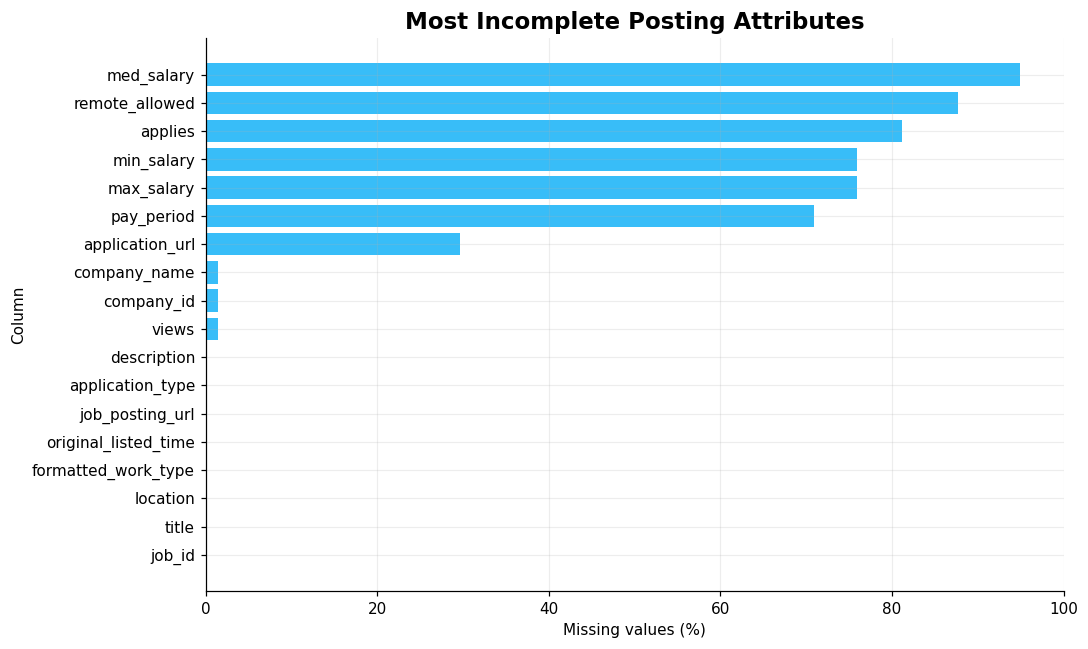

In [15]:
m=missing.head(18).sort_values("pct")
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(m.index,m.pct,color=CYAN)
ax.set(title="Most Incomplete Posting Attributes",xlabel="Missing values (%)",ylabel="Column")
ax.set_xlim(0,100); plt.tight_layout(); plt.show()

## 16. Dataset coverage

Count unique postings, companies, titles, and locations.

In [16]:
print("Job postings:",f"{len(jobs):,}")
for c in ["company_id","title","location"]:
    if c in jobs: print(f"Unique {c}:",f"{jobs[c].nunique(dropna=True):,}")

Job postings: 123,849
Unique company_id: 24,474
Unique title: 72,106
Unique location: 8,526


## 17. Most common job titles

Rank exact job-title strings and visualize the top 20.

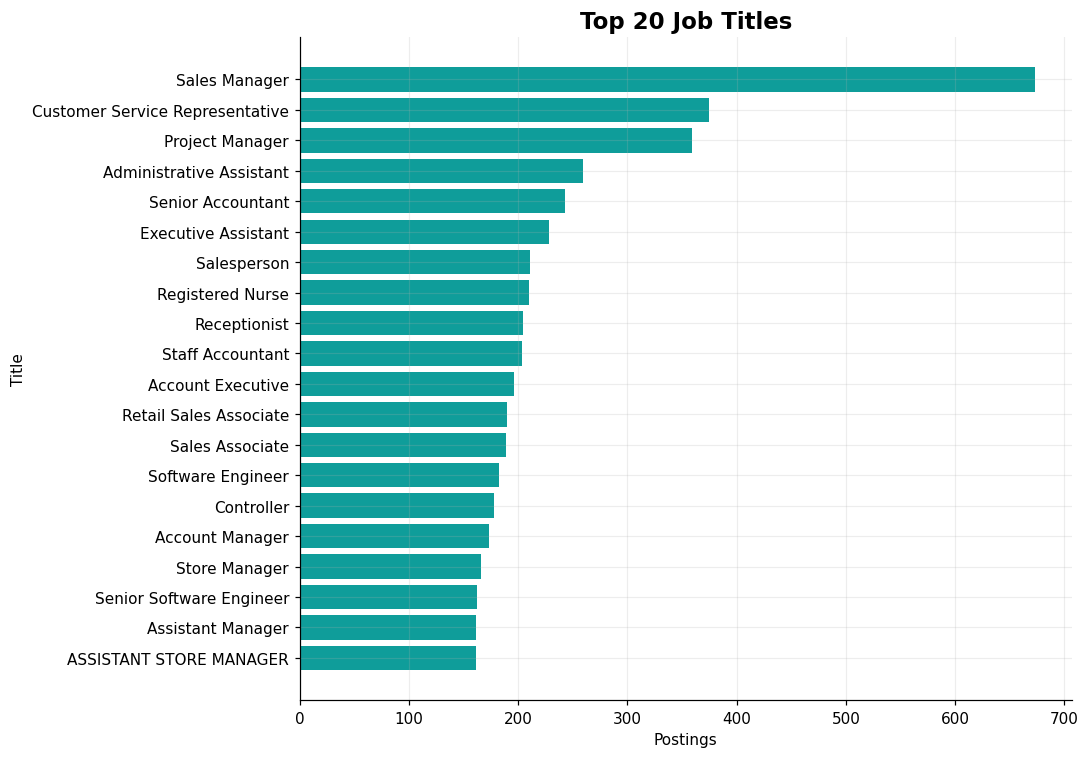

In [17]:
if "title" in jobs:
    counts=jobs.title.dropna().value_counts().head(20).sort_values()
    fig,ax=plt.subplots(figsize=(10,7))
    ax.barh(counts.index,counts.values,color=TEAL)
    ax.set(title="Top 20 Job Titles",xlabel="Postings",ylabel="Title")
    plt.tight_layout(); plt.show()

## 18. Map titles to broad role families

Apply transparent keyword rules to group common occupations into broad categories.

In [18]:
def role_family(title):
    t=str(title).lower()
    rules=[
    ("Data / Analytics",["data analyst","data scientist","analytics","business intelligence","bi analyst"]),
    ("Software Engineering",["software engineer","developer","programmer","backend","frontend","full stack"]),
    ("AI / Machine Learning",["machine learning","artificial intelligence","ai engineer","deep learning","nlp"]),
    ("Product / Project",["product manager","project manager","program manager"]),
    ("Design",["designer","design","ux","ui"]),
    ("Sales / Marketing",["sales","marketing","account executive","growth"]),
    ("Human Resources",["human resources","recruiter","talent acquisition","hr "]),
    ("Finance",["accountant","finance","financial analyst","controller"]),
    ("Operations",["operations","supply chain","logistics"]),
    ("Customer Support",["customer service","customer support","help desk"])]
    for family,keys in rules:
        if any(k in t for k in keys): return family
    return "Other / Unclassified"
if "title" in jobs:
    jobs["role_family"]=jobs.title.map(role_family)
    display(jobs.role_family.value_counts().to_frame("postings"))

,postings
role_family,
Other / Unclassified,91800
Sales / Marketing,10979
Software Engineering,4292
Design,4066
Product / Project,3172
Operations,2821
Finance,2775
Customer Support,1595
Data / Analytics,1146


## 19. Visualize role-family demand

Compare posting volumes across the broad title groups.

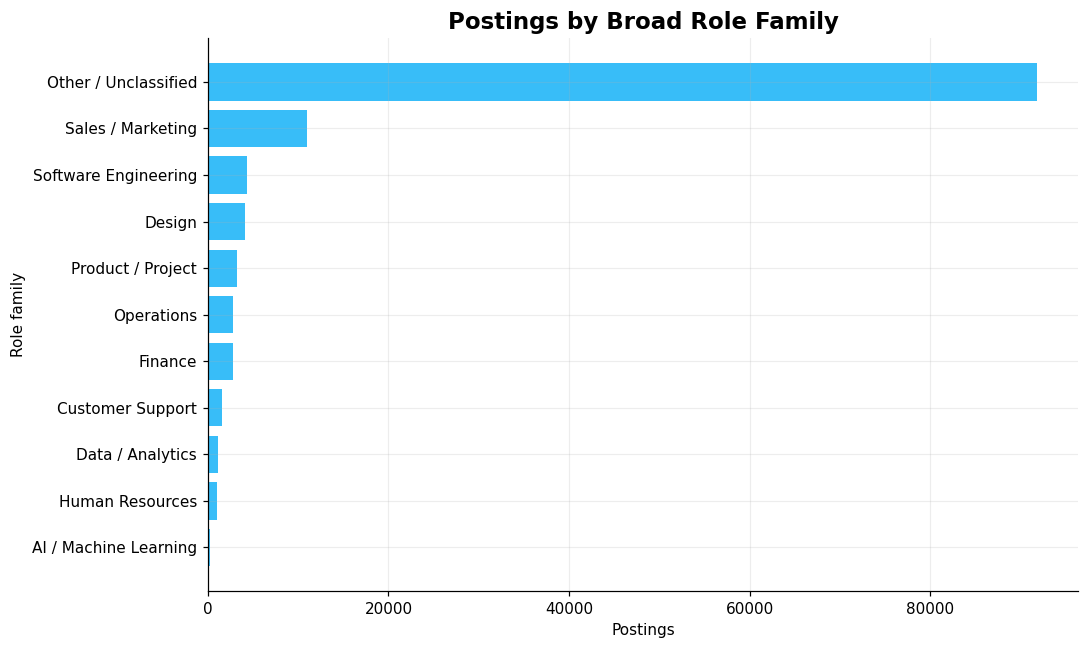

In [19]:
if "role_family" in jobs:
    s=jobs.role_family.value_counts().head(12).sort_values()
    fig,ax=plt.subplots(figsize=(10,6)); ax.barh(s.index,s.values,color=CYAN)
    ax.set(title="Postings by Broad Role Family",xlabel="Postings",ylabel="Role family")
    plt.tight_layout(); plt.show()

## 20. Work-type distribution

Explore full-time, part-time, contract, and other work-type labels.

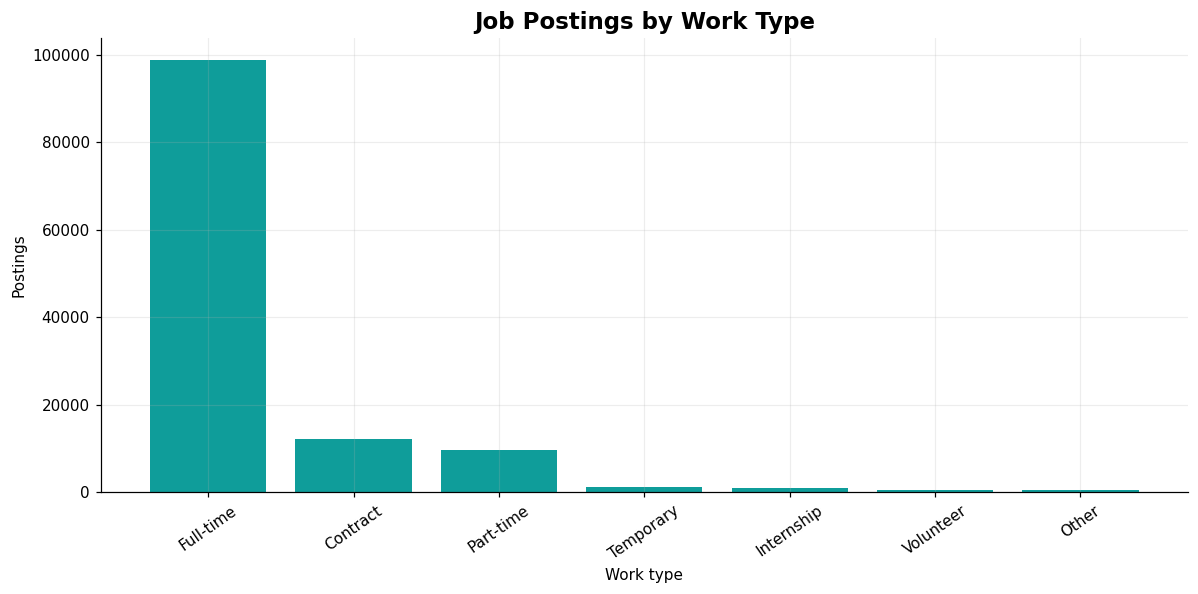

In [20]:
work_col="formatted_work_type" if "formatted_work_type" in jobs else "work_type"
if work_col in jobs:
    s=jobs[work_col].fillna("Not specified").value_counts().head(12)
    fig,ax=plt.subplots(); ax.bar(s.index.astype(str),s.values,color=TEAL)
    ax.set(title="Job Postings by Work Type",xlabel="Work type",ylabel="Postings")
    ax.tick_params(axis="x",rotation=35); plt.tight_layout(); plt.show()

## 21. Experience-level distribution

Measure how many postings are tagged as entry, associate, mid-senior, executive, or other levels.

,postings
formatted_experience_level,
Mid-Senior level,41489
Entry level,36708
Not specified,29409
Associate,9826
Director,3746
Internship,1449
Executive,1222


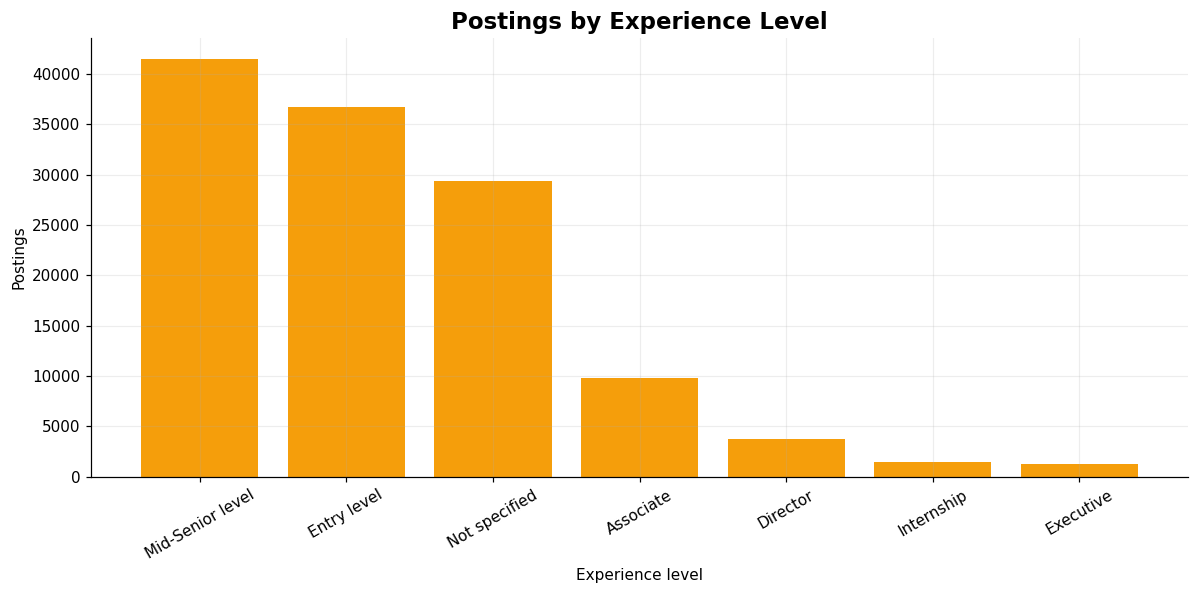

In [21]:
if "formatted_experience_level" in jobs:
    s=jobs.formatted_experience_level.fillna("Not specified").value_counts()
    display(s.to_frame("postings"))
    fig,ax=plt.subplots(); ax.bar(s.index.astype(str),s.values,color=ORANGE)
    ax.set(title="Postings by Experience Level",xlabel="Experience level",ylabel="Postings")
    ax.tick_params(axis="x",rotation=30); plt.tight_layout(); plt.show()

## 22. Remote-work indicator

Inspect the remote_allowed field and distinguish missing values from explicit zero values.

,postings
remote_label,
Not specified,108603
Remote allowed,15246


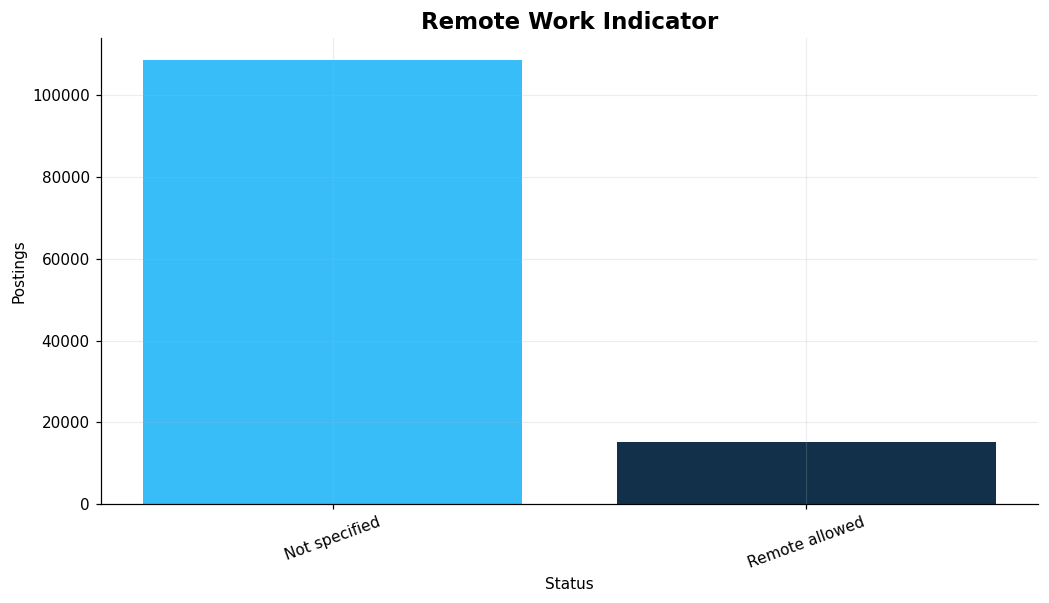

In [22]:
if "remote_allowed" in jobs:
    jobs["remote_label"]=jobs.remote_allowed.map({1:"Remote allowed",0:"Not marked remote"}).fillna("Not specified")
    s=jobs.remote_label.value_counts()
    display(s.to_frame("postings"))
    fig,ax=plt.subplots(); ax.bar(s.index,s.values,color=[CYAN,NAVY,ORANGE][:len(s)])
    ax.set(title="Remote Work Indicator",xlabel="Status",ylabel="Postings")
    ax.tick_params(axis="x",rotation=20); plt.show()

## 23. Remote status by work type

Compare remote-flag proportions within work-type groups.

remote_label,Not specified,Remote allowed
formatted_work_type,,
Contract,73.90,26.10
Full-time,88.90,11.10
Internship,78.60,21.40
Other,84.40,15.60
Part-time,93.90,6.10
Temporary,92.90,7.10
Volunteer,78.60,21.40


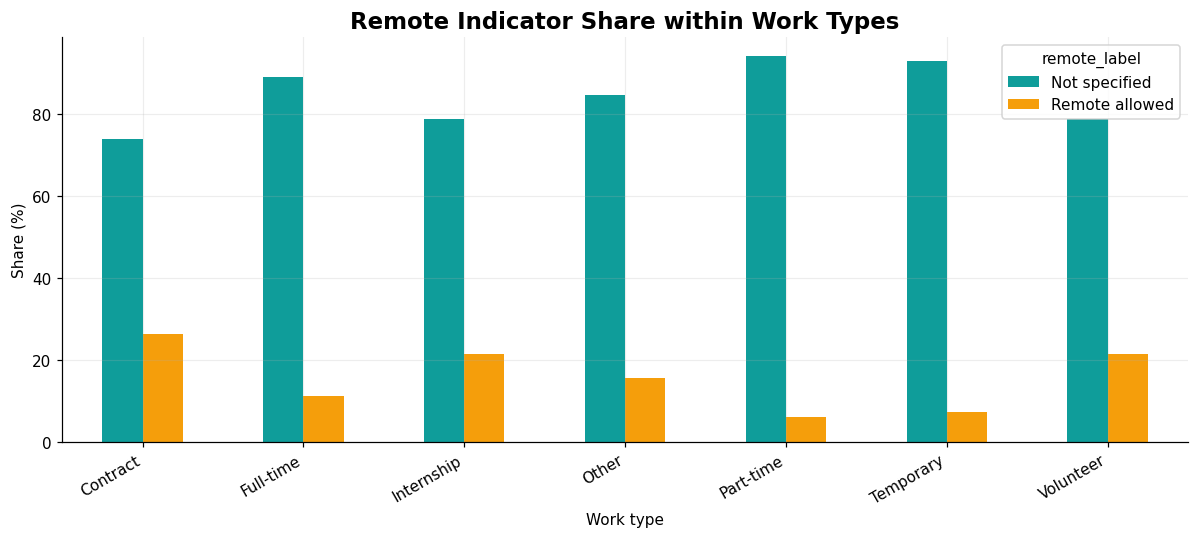

In [23]:
if "remote_label" in jobs and work_col in jobs:
    ct=pd.crosstab(jobs[work_col],jobs.remote_label,normalize="index")*100
    display(ct.round(1))
    ct.plot(kind="bar",figsize=(11,5),color=[TEAL,ORANGE,NAVY])
    plt.title("Remote Indicator Share within Work Types"); plt.ylabel("Share (%)")
    plt.xlabel("Work type"); plt.xticks(rotation=30,ha="right"); plt.tight_layout(); plt.show()

## 24. Most common posting locations

Rank exact location strings. These may combine city, state, and country.

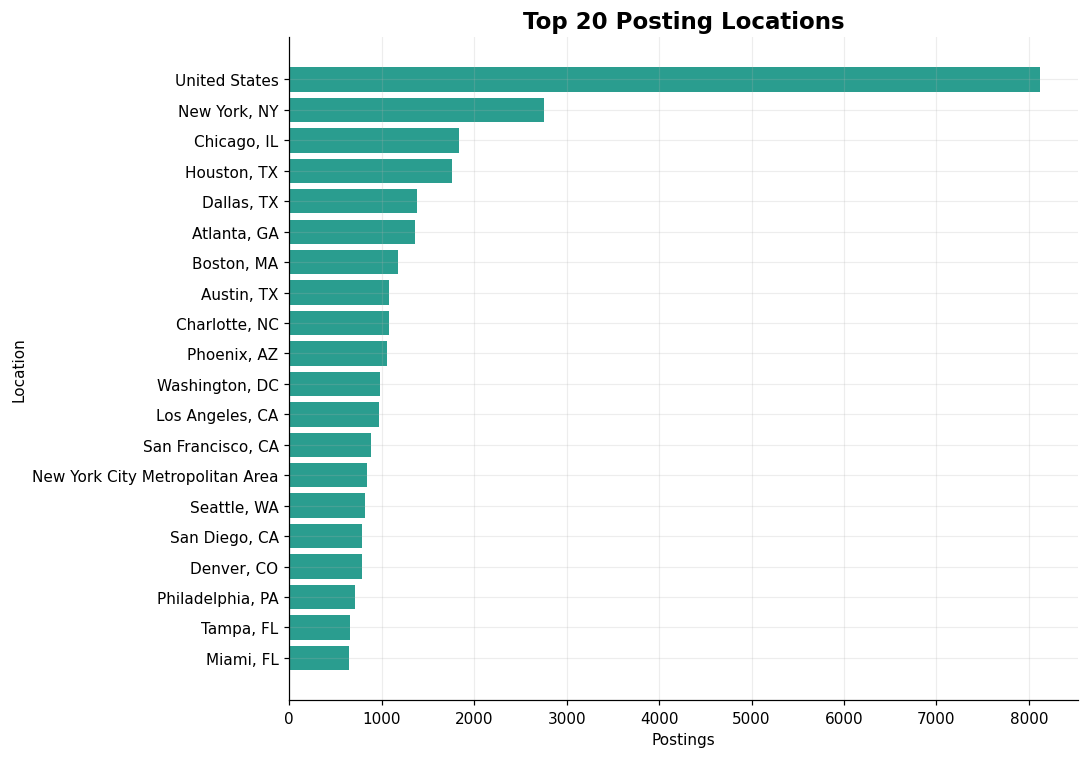

In [24]:
if "location" in jobs:
    s=jobs.location.dropna().value_counts().head(20).sort_values()
    fig,ax=plt.subplots(figsize=(10,7)); ax.barh(s.index,s.values,color=GREEN)
    ax.set(title="Top 20 Posting Locations",xlabel="Postings",ylabel="Location")
    plt.tight_layout(); plt.show()

## 25. Split location strings

Extract the first two comma-separated location components as rough descriptive fields.

In [25]:
if "location" in jobs:
    parts=jobs.location.str.split(",",n=2,expand=True)
    jobs["location_part_1"]=parts[0].str.strip()
    jobs["location_part_2"]=parts[1].str.strip() if parts.shape[1]>1 else pd.NA
    display(jobs[["location","location_part_1","location_part_2"]].head(8))

,location,location_part_1,location_part_2
0,"Princeton, NJ",Princeton,NJ
1,"Fort Collins, CO",Fort Collins,CO
2,"Cincinnati, OH",Cincinnati,OH
3,"New Hyde Park, NY",New Hyde Park,NY
4,"Burlington, IA",Burlington,IA
5,"Raleigh, NC",Raleigh,NC
6,United States,United States,<NA>
7,"San Francisco, CA",San Francisco,CA


## 26. Application and view activity

Summarize views and application counts with robust percentiles.

In [26]:
activity_cols=[c for c in ["views","applies"] if c in jobs]
if activity_cols:
    display(jobs[activity_cols].describe(percentiles=[.5,.75,.9,.95,.99]).T)

,count,mean,std,min,50%,75%,90%,95%,99%,max
views,"122,160.00",14.62,85.90,1.00,4.00,8.00,23.00,48.00,177.00,"9,975.00"
applies,"23,320.00",10.59,29.05,1.00,3.00,8.00,24.00,45.00,133.81,967.00


## 27. Visualize activity distributions

Clip only the displayed histogram at the 99th percentile to make the main distribution visible.

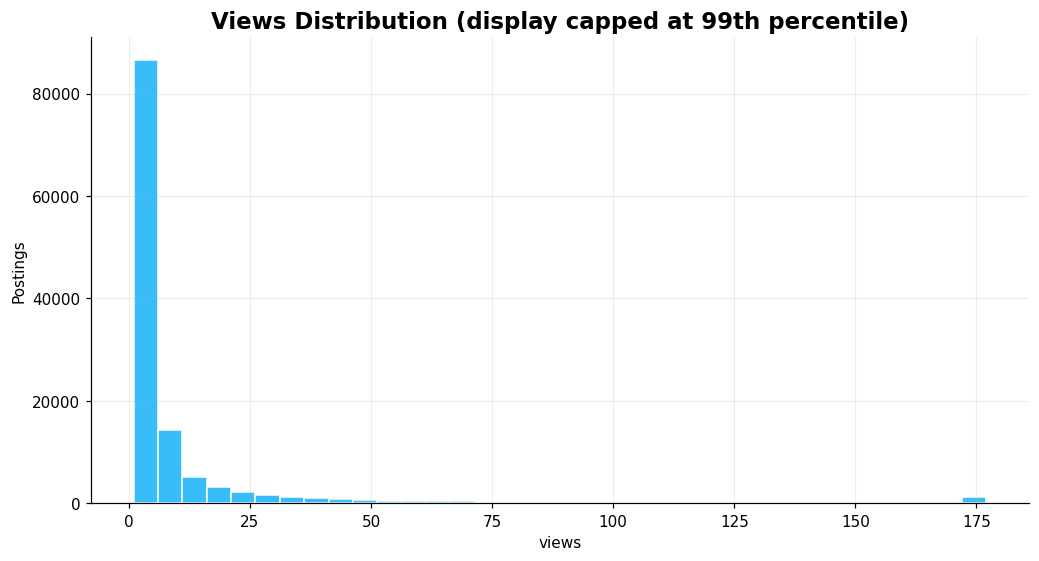

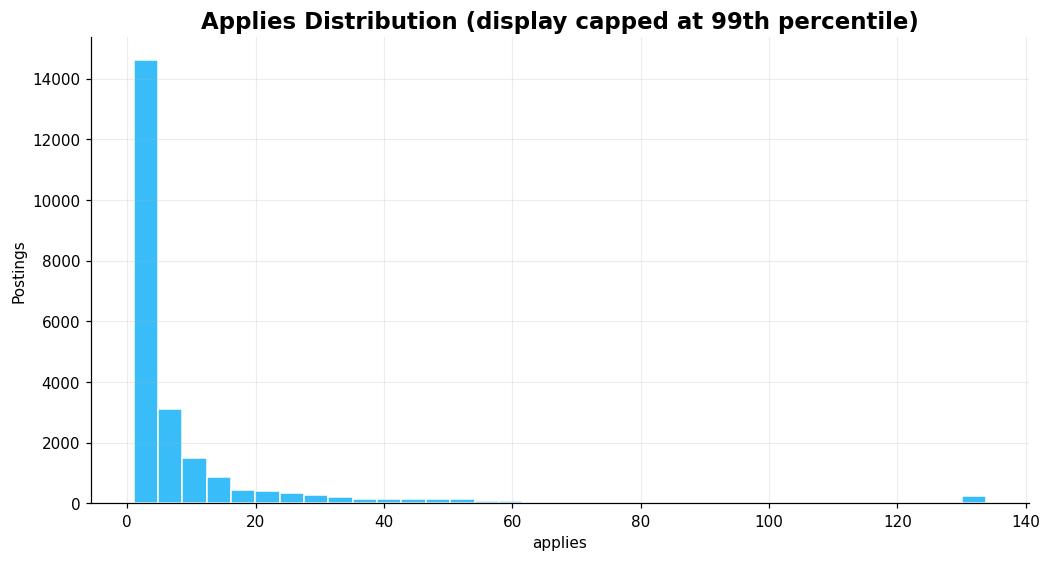

In [27]:
for c in activity_cols:
    v=jobs[c].dropna()
    if len(v):
        fig,ax=plt.subplots(); ax.hist(v.clip(upper=v.quantile(.99)),bins=35,color=CYAN,edgecolor="white")
        ax.set(title=f"{c.title()} Distribution (display capped at 99th percentile)",xlabel=c,ylabel="Postings")
        plt.show()

## 28. Application-to-view ratio

Calculate a rough ratio where both views and applications are available and views are nonzero.

In [28]:
if {"views","applies"}.issubset(jobs.columns):
    jobs["application_view_ratio"]=jobs.applies/jobs.views.replace(0,np.nan)
    display(jobs.application_view_ratio.replace([np.inf,-np.inf],np.nan).describe().to_frame())

,application_view_ratio
count,"23,319.00"
mean,0.18
std,0.11
min,0.00
25%,0.09
50%,0.15
75%,0.24
max,1.00


## 29. Salary-field availability

Review salary values, currencies, and pay periods before attempting comparisons.

In [29]:
salary_cols=[c for c in ["min_salary","med_salary","max_salary","pay_period","currency","compensation_type"] if c in jobs]
display(jobs[salary_cols].head(10))
display((jobs[salary_cols].isna().mean()*100).rename("missing_pct").to_frame().round(1))

,min_salary,med_salary,max_salary,pay_period,currency,compensation_type
0,17.00,NaN,20.00,HOURLY,USD,BASE_SALARY
1,30.00,NaN,50.00,HOURLY,USD,BASE_SALARY
2,"45,000.00",NaN,"65,000.00",YEARLY,USD,BASE_SALARY
3,"140,000.00",NaN,"175,000.00",YEARLY,USD,BASE_SALARY
4,"60,000.00",NaN,"80,000.00",YEARLY,USD,BASE_SALARY
5,14.00,NaN,20.00,HOURLY,USD,BASE_SALARY
6,"60,000.00",NaN,"300,000.00",YEARLY,USD,BASE_SALARY
7,"90,000.00",NaN,"120,000.00",YEARLY,USD,BASE_SALARY
8,NaN,NaN,NaN,<NA>,<NA>,<NA>
9,NaN,350.00,NaN,MONTHLY,USD,BASE_SALARY


,missing_pct
min_salary,75.90
med_salary,94.90
max_salary,75.90
pay_period,70.90
currency,70.90
compensation_type,70.90


## 30. Currency and pay-period composition

Count salary records by currency and payment frequency.

In [30]:
for c in ["currency","pay_period","compensation_type"]:
    if c in jobs: display(jobs[c].value_counts(dropna=False).head(20).to_frame("records"))

,records
currency,
<NA>,87776
USD,36058
EUR,6
CAD,3
BBD,2
AUD,2
GBP,2


,records
pay_period,
<NA>,87776
YEARLY,20628
HOURLY,14741
MONTHLY,518
WEEKLY,177
BIWEEKLY,9


,records
compensation_type,
<NA>,87776
BASE_SALARY,36073


## 31. Construct a salary midpoint

Use median salary where present; otherwise use the midpoint of minimum and maximum salary.

In [31]:
if any(c in jobs for c in ["min_salary","med_salary","max_salary"]):
    med=jobs["med_salary"] if "med_salary" in jobs else pd.Series(np.nan,index=jobs.index)
    lo=jobs["min_salary"] if "min_salary" in jobs else pd.Series(np.nan,index=jobs.index)
    hi=jobs["max_salary"] if "max_salary" in jobs else pd.Series(np.nan,index=jobs.index)
    jobs["salary_midpoint"]=med.where(med.notna(),(lo+hi)/2)
    jobs.loc[jobs.salary_midpoint<0,"salary_midpoint"]=np.nan
    print("Usable salary values:",jobs.salary_midpoint.notna().sum())

Usable salary values: 36073


## 32. Salary summaries by currency and period

Keep each currency/pay-period combination separate to avoid invalid comparisons.

In [32]:
group_cols=[c for c in ["currency","pay_period"] if c in jobs]
if group_cols and "salary_midpoint" in jobs:
    salary_summary=jobs.dropna(subset=["salary_midpoint"]).groupby(group_cols).salary_midpoint.agg(
        postings="count",median="median",mean="mean",q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75))
    display(salary_summary.sort_values("postings",ascending=False).head(25).round(2))

postings     median       mean        q25        q75
currency pay_period                                                      
USD      YEARLY         20616 102,000.00 119,719.73  72,500.00 142,500.00
         HOURLY         14738      25.25     158.98      19.55      41.50
         MONTHLY          518   4,469.50   5,340.23   2,362.25   6,842.42
         WEEKLY           177   2,099.00   2,145.38   1,917.00   2,301.12
         BIWEEKLY           9  60,492.50  48,025.44   2,805.50  72,976.50
EUR      YEARLY             6  29,736.00  29,862.00  26,934.00  41,184.00
AUD      YEARLY             2  95,919.50  95,919.50  95,919.50  95,919.50
GBP      HOURLY             2      12.50      12.50      12.25      12.75
BBD      YEARLY             2  58,750.00  58,750.00  57,500.00  60,000.00
CAD      YEARLY             2 113,150.00 113,150.00 106,825.00 119,475.00
         HOURLY             1      57.50      57.50      57.50      57.50

## 33. Plot common salary distributions

Plot up to four most common currency/pay-period groups separately.

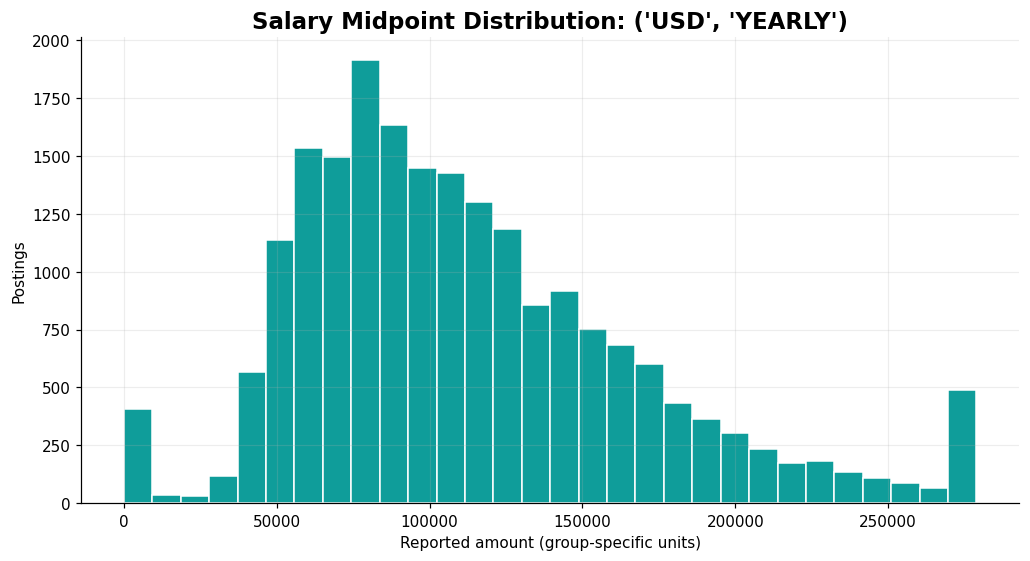

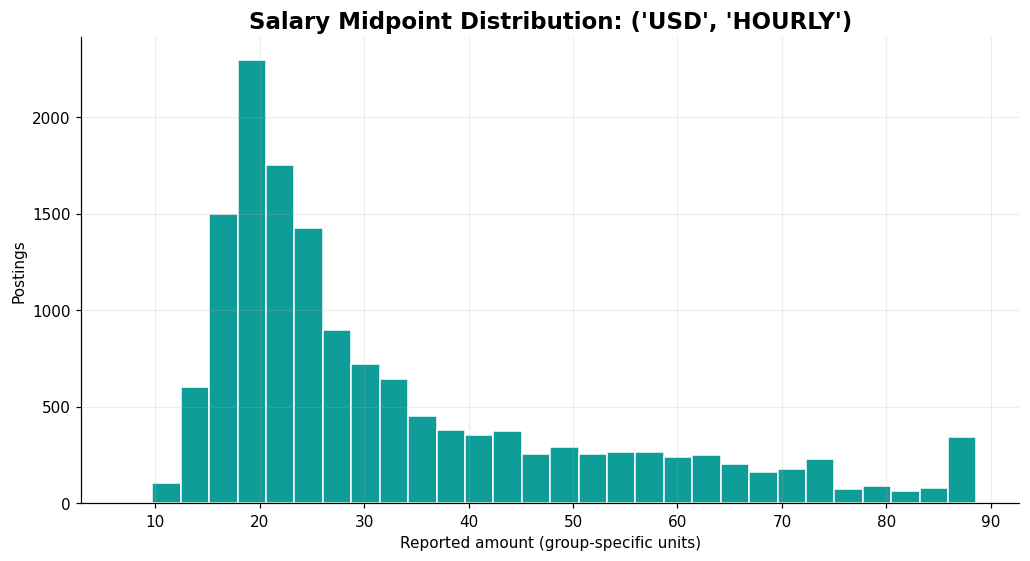

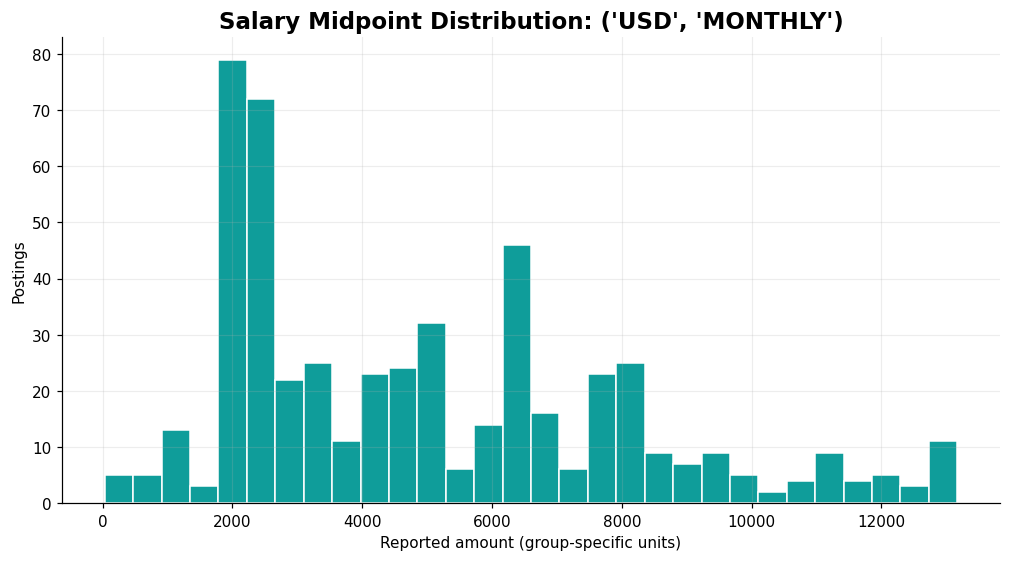

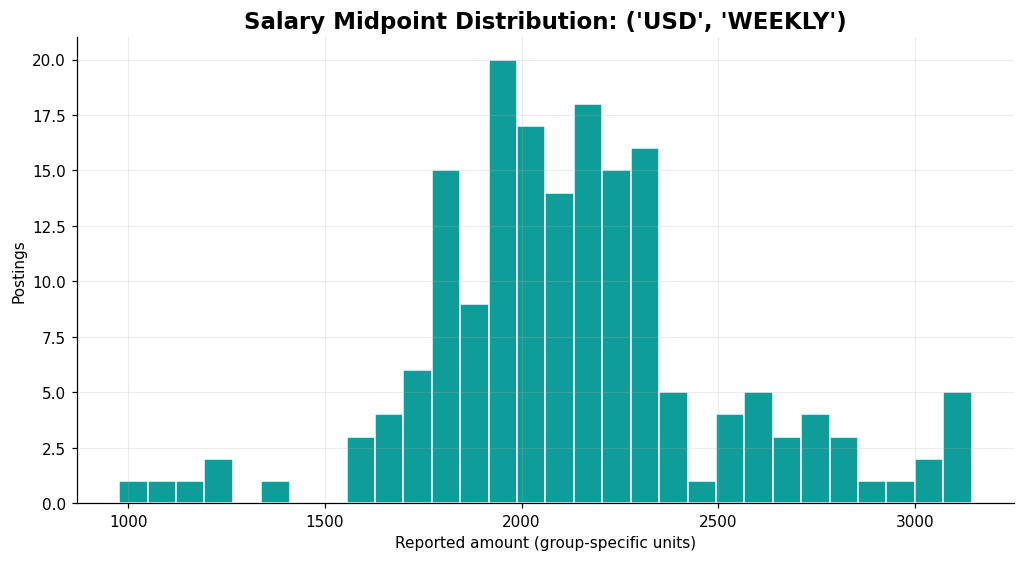

In [33]:
if group_cols and "salary_midpoint" in jobs:
    gs=jobs.dropna(subset=["salary_midpoint"]).groupby(group_cols).size().sort_values(ascending=False)
    for key in list(gs.head(4).index):
        mask=pd.Series(True,index=jobs.index)
        for col,val in zip(group_cols,key if isinstance(key,tuple) else (key,)): mask &= jobs[col].eq(val)
        v=jobs.loc[mask,"salary_midpoint"].dropna()
        if len(v)>=5:
            fig,ax=plt.subplots(); ax.hist(v.clip(upper=v.quantile(.98)),bins=30,color=TEAL,edgecolor="white")
            ax.set(title=f"Salary Midpoint Distribution: {key}",xlabel="Reported amount (group-specific units)",ylabel="Postings")
            plt.show()

## 34. Salary by experience level

Compare median salary within the most common currency/pay-period group only.

,count,median
formatted_experience_level,,
Internship,51,"65,000.00"
Entry level,3203,"75,400.00"
Associate,2267,"80,500.00"
Mid-Senior level,8489,"115,000.00"
Director,1203,"167,500.00"
Executive,348,"200,000.00"


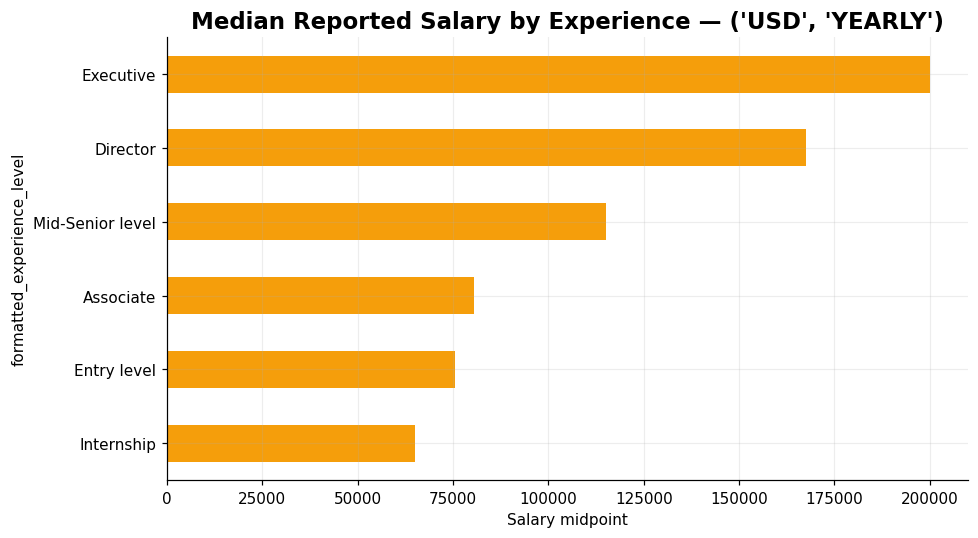

In [34]:
if "salary_midpoint" in jobs and "formatted_experience_level" in jobs and group_cols:
    v=jobs.dropna(subset=["salary_midpoint","formatted_experience_level"]+group_cols)
    sizes=v.groupby(group_cols).size().sort_values(ascending=False)
    if len(sizes):
        key=sizes.index[0]; mask=pd.Series(True,index=v.index)
        for col,val in zip(group_cols,key if isinstance(key,tuple) else (key,)): mask &= v[col].eq(val)
        comp=v.loc[mask].groupby("formatted_experience_level").salary_midpoint.agg(["count","median"]).sort_values("median")
        display(comp.round(2))
        comp["median"].plot(kind="barh",figsize=(9,5),color=ORANGE)
        plt.title(f"Median Reported Salary by Experience — {key}"); plt.xlabel("Salary midpoint")
        plt.tight_layout(); plt.show()

## 35. Join company attributes

Merge company metadata onto postings while preserving postings with unmatched company IDs.

In [35]:
job_company=jobs.copy()
if companies is not None and {"company_id"}.issubset(jobs.columns) and "company_id" in companies:
    cols=[c for c in ["company_id","name","company_size","country","state","city","description"] if c in companies]
    dim=companies[cols].drop_duplicates("company_id")
    job_company=job_company.merge(dim,on="company_id",how="left",suffixes=("","_company"))
    print("Joined shape:",job_company.shape)
else: print("Company enrichment unavailable.")

Joined shape: (123849, 47)


## 36. Companies with the most postings

Rank employer names by the number of associated job postings.

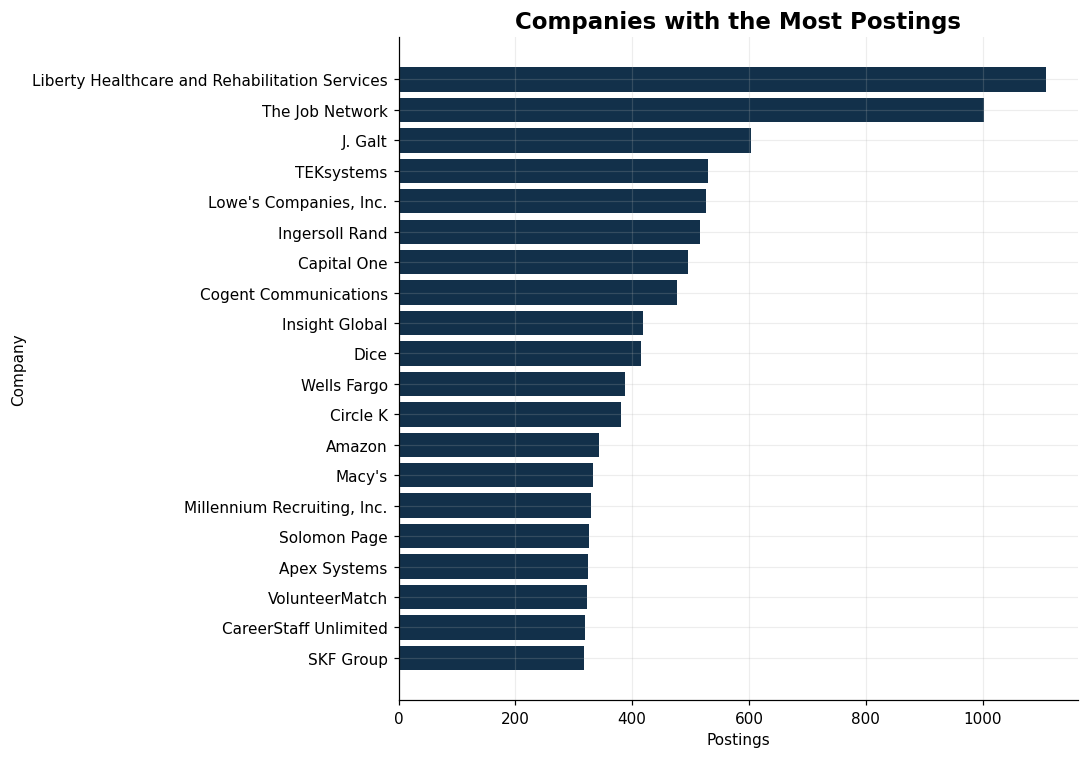

In [36]:
if "name" in job_company:
    s=job_company.name.dropna().value_counts().head(20).sort_values()
    fig,ax=plt.subplots(figsize=(10,7)); ax.barh(s.index,s.values,color=NAVY)
    ax.set(title="Companies with the Most Postings",xlabel="Postings",ylabel="Company")
    plt.tight_layout(); plt.show()

## 37. Company-size distribution

Explore LinkedIn company-size categories represented among the postings.

,posting_count
company_size,
1.0,9123
2.0,13389
3.0,9358
4.0,8894
5.0,22453
6.0,11146
7.0,42779
Not specified,6707


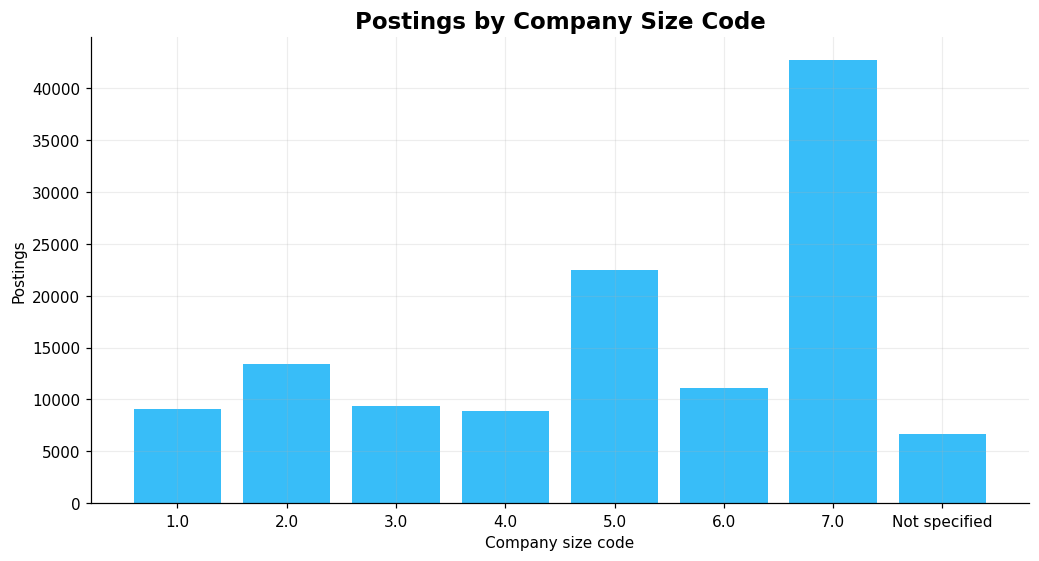

In [37]:
if "company_size" in job_company:
    s=job_company.company_size.fillna("Not specified").astype(str).value_counts().sort_index()
    display(s.to_frame("posting_count"))
    fig,ax=plt.subplots(); ax.bar(s.index,s.values,color=CYAN)
    ax.set(title="Postings by Company Size Code",xlabel="Company size code",ylabel="Postings")
    plt.show()

## 38. Company headquarters countries

Summarize postings by the headquarters country listed in the company table.

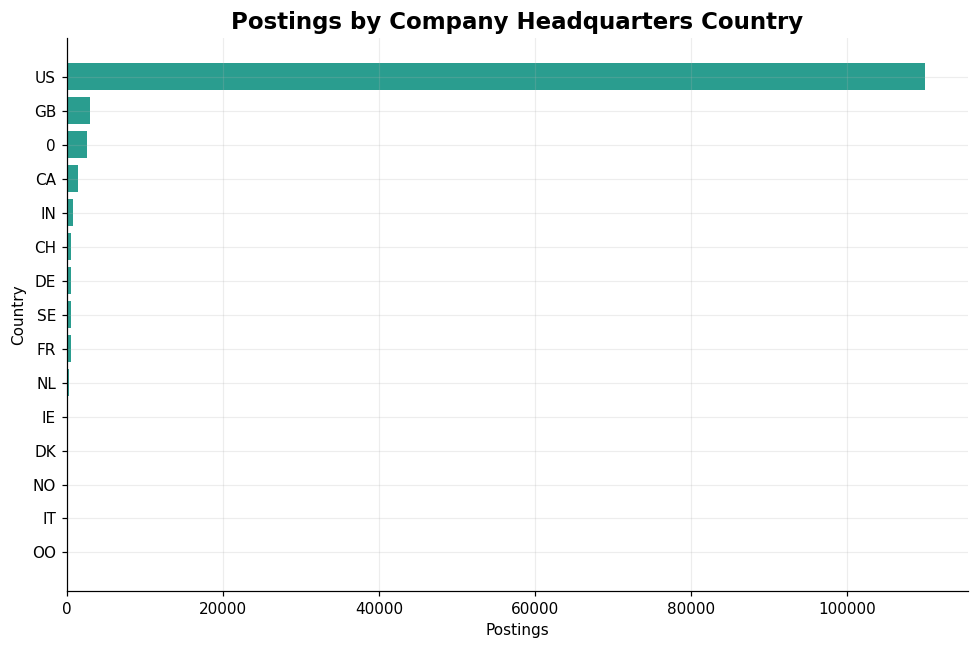

In [38]:
if "country" in job_company:
    s=job_company.country.dropna().value_counts().head(15).sort_values()
    fig,ax=plt.subplots(figsize=(9,6)); ax.barh(s.index.astype(str),s.values,color=GREEN)
    ax.set(title="Postings by Company Headquarters Country",xlabel="Postings",ylabel="Country")
    plt.tight_layout(); plt.show()

## 39. Inspect employee-count records

Review employee and follower counts and their time-recorded field.

In [39]:
if employee_counts is not None:
    print(employee_counts.shape,employee_counts.columns.tolist())
    display(employee_counts.head())

(35787, 4) ['company_id', 'employee_count', 'follower_count', 'time_recorded']


,company_id,employee_count,follower_count,time_recorded
0,391906,186,32508,1712346173
1,22292832,311,4471,1712346173
2,20300,1053,6554,1712346173
3,3570660,383,35241,1712346173
4,878353,52,26397,1712346173


## 40. Explore employee and follower counts

Use log-scaled histograms because company size and follower counts are typically highly skewed.

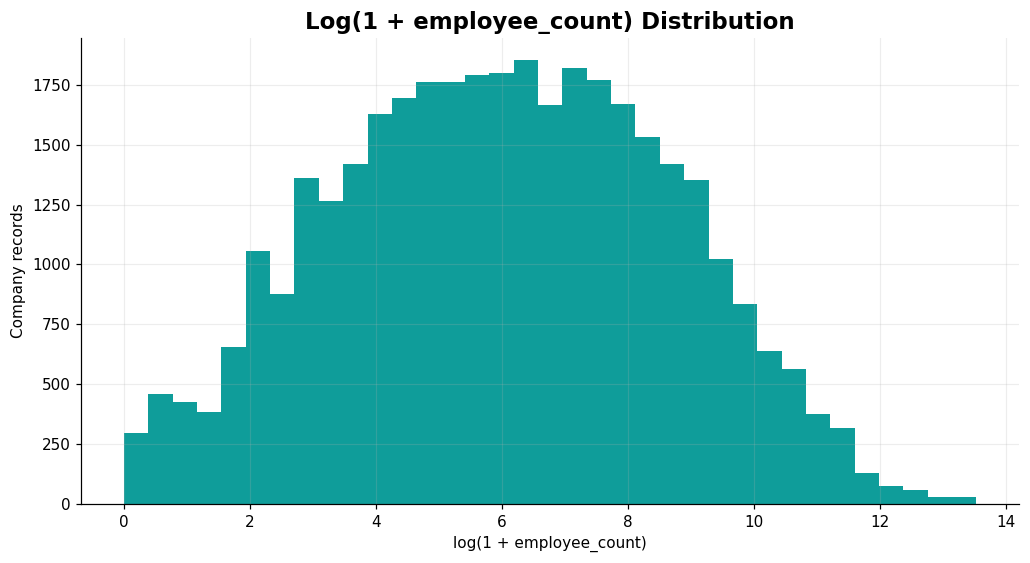

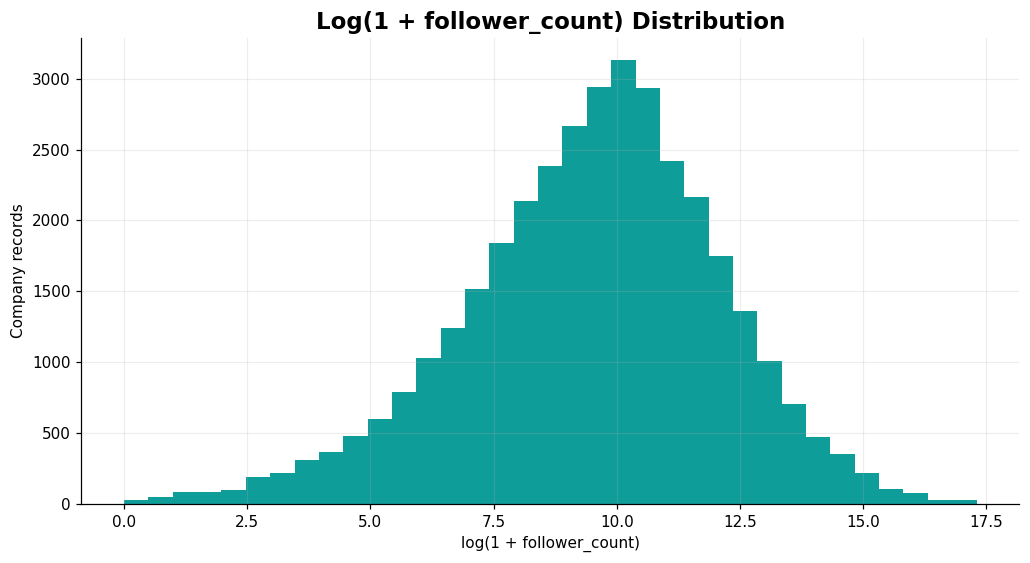

In [40]:
if employee_counts is not None:
    for c in ["employee_count","follower_count"]:
        if c in employee_counts:
            v=pd.to_numeric(employee_counts[c],errors="coerce").dropna()
            v=v[v>=0]
            if len(v):
                fig,ax=plt.subplots(); ax.hist(np.log1p(v),bins=35,color=TEAL)
                ax.set(title=f"Log(1 + {c}) Distribution",xlabel=f"log(1 + {c})",ylabel="Company records")
                plt.show()

## 41. Inspect job-skill mappings

Review the job-to-skill bridge table and discover its key columns.

In [41]:
if job_skills is not None:
    print("Shape:",job_skills.shape,"Columns:",job_skills.columns.tolist())
    display(job_skills.head())
else: print("job_skills.csv not available.")

Shape: (213768, 2) Columns: ['job_id', 'skill_abr']


,job_id,skill_abr
0,3884428798,MRKT
1,3884428798,PR
2,3884428798,WRT
3,3887473071,SALE
4,3887465684,FIN


## 42. Resolve skill names and rank skills

Use the skill lookup table when a shared ID column and a readable label are available.

In [42]:
skill_counts=pd.Series(dtype=int)
if job_skills is not None:
    skill_key=next((c for c in job_skills if "skill" in c.lower()),None)
    if skills is not None and skill_key:
        shared=[c for c in skills if c in job_skills]
        label=next((c for c in skills if c.lower() in {"skill_name","name","skill"}),None)
        if shared and label:
            joined=job_skills.merge(skills[[shared[0],label]].drop_duplicates(shared[0]),on=shared[0],how="left")
            skill_counts=joined[label].fillna("Unknown").value_counts().head(25)
    if skill_counts.empty and skill_key:
        skill_counts=job_skills[skill_key].value_counts().head(25)
display(skill_counts.to_frame("skill_links"))

,skill_links
skill_name,
Information Technology,26137
Sales,22475
Management,20861
Manufacturing,18185
Health Care Provider,17369
Business Development,14290
Engineering,13009
Other,12608
Finance,8540


## 43. Visualize top skills

Plot the most frequent skill labels or IDs linked to job postings.

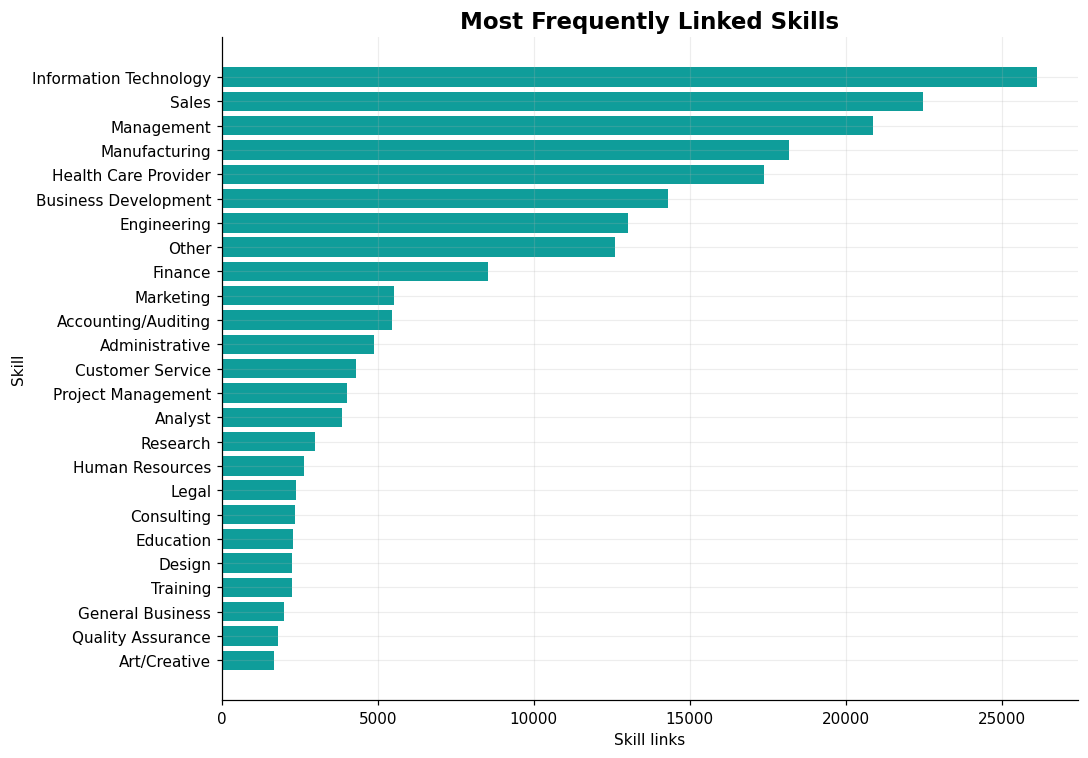

In [43]:
if len(skill_counts):
    s=skill_counts.sort_values()
    fig,ax=plt.subplots(figsize=(10,7)); ax.barh(s.index.astype(str),s.values,color=TEAL)
    ax.set(title="Most Frequently Linked Skills",xlabel="Skill links",ylabel="Skill")
    plt.tight_layout(); plt.show()
else: print("No skill frequency values could be derived.")

## 44. Inspect industry mappings

Review the job-industry table and industry lookup schema.

In [44]:
if job_industries is not None:
    print(job_industries.shape,job_industries.columns.tolist())
    display(job_industries.head())
if industries is not None:
    print("Industry lookup:",industries.columns.tolist())
    display(industries.head())

(164808, 2) ['job_id', 'industry_id']


,job_id,industry_id
0,3884428798,82
1,3887473071,48
2,3887465684,41
3,3887467939,82
4,3887467939,80


Industry lookup: ['industry_id', 'industry_name']


,industry_id,industry_name
0,1,Defense and Space Manufacturing
1,3,Computer Hardware Manufacturing
2,4,Software Development
3,5,Computer Networking Products
4,6,"Technology, Information and Internet"


## 45. Rank industries

Resolve industry labels from the lookup table where possible; otherwise show the mapped IDs.

In [45]:
industry_counts=pd.Series(dtype=int)
if job_industries is not None:
    ikey=next((c for c in job_industries if "industry" in c.lower()),None)
    if ikey:
        if industries is not None:
            shared=[c for c in industries if c in job_industries]
            label=next((c for c in industries if c.lower() in {"industry_name","name","industry"}),None)
            if shared and label:
                ji=job_industries.merge(industries[[shared[0],label]].drop_duplicates(shared[0]),on=shared[0],how="left")
                industry_counts=ji[label].fillna("Unknown").value_counts().head(20)
        if industry_counts.empty: industry_counts=job_industries[ikey].value_counts().head(20)
display(industry_counts.to_frame("industry_links"))

,industry_links
industry_name,
Hospitals and Health Care,18326
Retail,11033
IT Services and IT Consulting,10396
Staffing and Recruiting,9005
Financial Services,8535
Software Development,5091
Manufacturing,3689
Construction,3445
Banking,2923


## 46. Visualize leading industries

Plot the most frequently represented industries or industry identifiers.

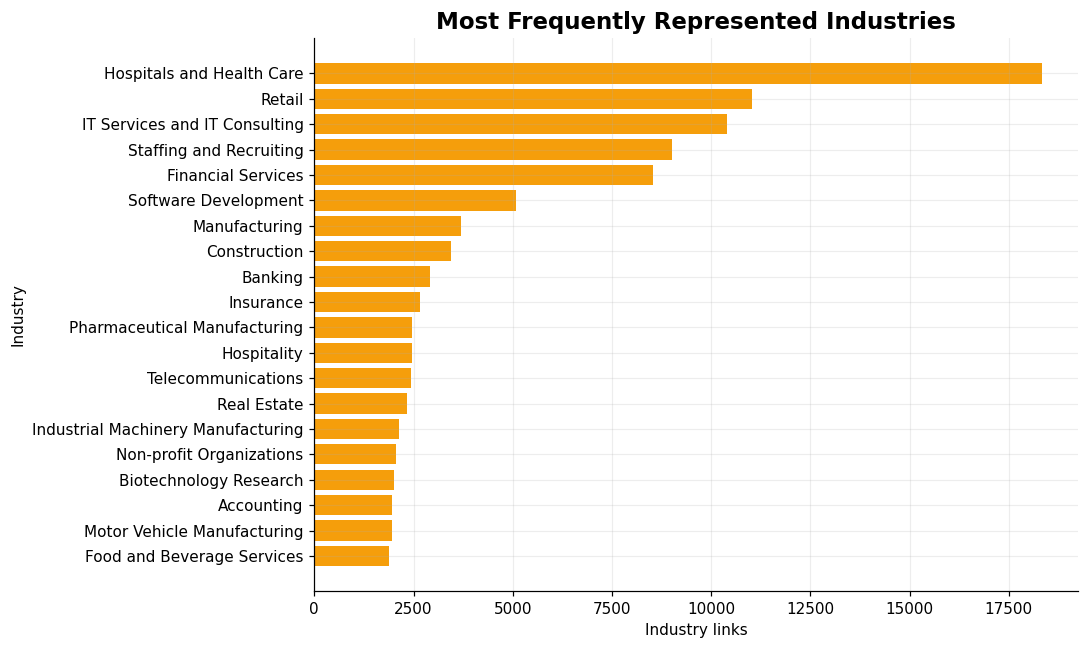

In [46]:
if len(industry_counts):
    s=industry_counts.sort_values()
    fig,ax=plt.subplots(figsize=(10,6)); ax.barh(s.index.astype(str),s.values,color=ORANGE)
    ax.set(title="Most Frequently Represented Industries",xlabel="Industry links",ylabel="Industry")
    plt.tight_layout(); plt.show()
else: print("No industry counts available.")

## 47. Explore benefits

Count benefit tags associated with job postings.

In [47]:
if benefits is not None:
    print("Benefits shape:",benefits.shape,benefits.columns.tolist())
    display(benefits.head())
    if "type" in benefits:
        benefit_counts=benefits.type.fillna("Not specified").value_counts()
        display(benefit_counts.head(25).to_frame("benefit_tags"))

Benefits shape: (67943, 3) ['job_id', 'inferred', 'type']


,job_id,inferred,type
0,3887473071,0,Medical insurance
1,3887473071,0,Vision insurance
2,3887473071,0,Dental insurance
3,3887473071,0,401(k)
4,3887473071,0,Student loan assistance


,benefit_tags
type,
401(k),24231
Medical insurance,9873
Vision insurance,9309
Disability insurance,7930
Dental insurance,6868
Tuition assistance,2614
Commuter benefits,2226
Paid maternity leave,1808
Paid paternity leave,1540


## 48. Explicit versus inferred benefits

Inspect the inferred flag to understand whether benefit tags were explicitly identified or inferred from text.

,records
inferred,
1,40424
0,27519


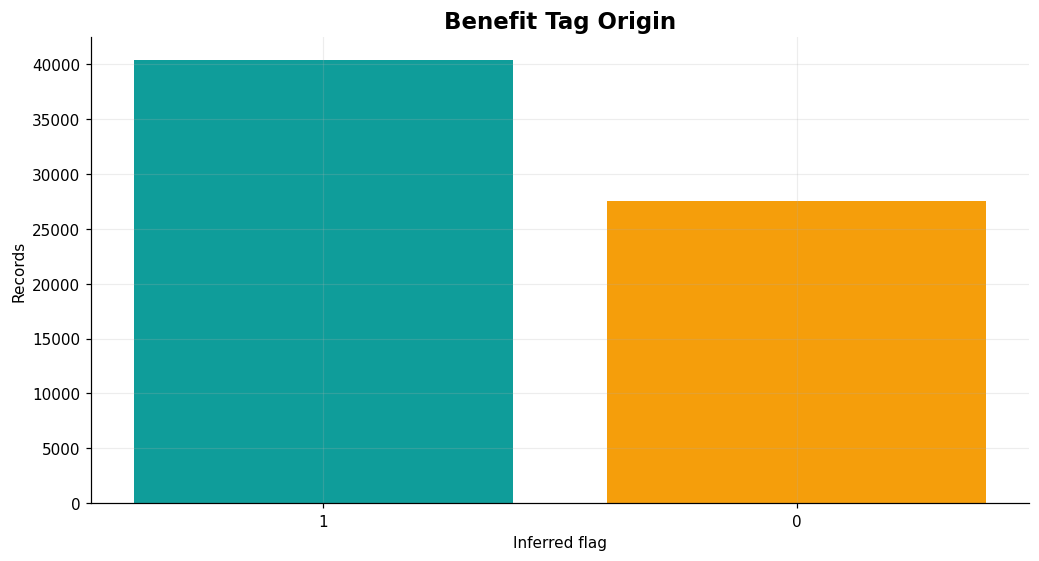

In [48]:
if benefits is not None and "inferred" in benefits:
    s=benefits.inferred.fillna("Unknown").astype(str).value_counts()
    display(s.to_frame("records"))
    fig,ax=plt.subplots(); ax.bar(s.index,s.values,color=[TEAL,ORANGE,NAVY][:len(s)])
    ax.set(title="Benefit Tag Origin",xlabel="Inferred flag",ylabel="Records")
    plt.show()

## 49. Prepare descriptions for NLP

Select non-empty descriptions and cap the sample size to keep execution fast.

In [49]:
if "description" in jobs:
    text_data=jobs[["description"]].dropna().copy()
    text_data["description"]=text_data.description.astype(str)
    text_data=text_data[text_data.description.str.len()>30]
    text_sample=text_data.sample(min(12000,len(text_data)),random_state=RANDOM_STATE) if len(text_data) else text_data
else: text_sample=pd.DataFrame(columns=["description"])
print("Usable descriptions:",len(text_data) if "text_data" in globals() else 0)
print("NLP sample:",len(text_sample))

Usable descriptions: 123803
NLP sample: 12000


## 50. Extract frequent terms and bigrams

Use a compact CountVectorizer vocabulary to identify recurring language in job descriptions.

In [50]:
from sklearn.feature_extraction.text import CountVectorizer
term_freq=pd.Series(dtype=float)
if len(text_sample):
    cv=CountVectorizer(stop_words="english",max_features=60,ngram_range=(1,2),min_df=5,max_df=.85)
    mat=cv.fit_transform(text_sample.description)
    term_freq=pd.Series(np.asarray(mat.sum(axis=0)).ravel(),index=cv.get_feature_names_out()).sort_values(ascending=False)
display(term_freq.head(25).to_frame("frequency"))

,frequency
work,33983
team,24087
skills,18730
including,17841
job,17608
ability,16964
management,16658
business,16570
required,16103
time,15273


## 51. Visualize description terms

Plot the most frequent terms and two-word phrases extracted from the sampled descriptions.

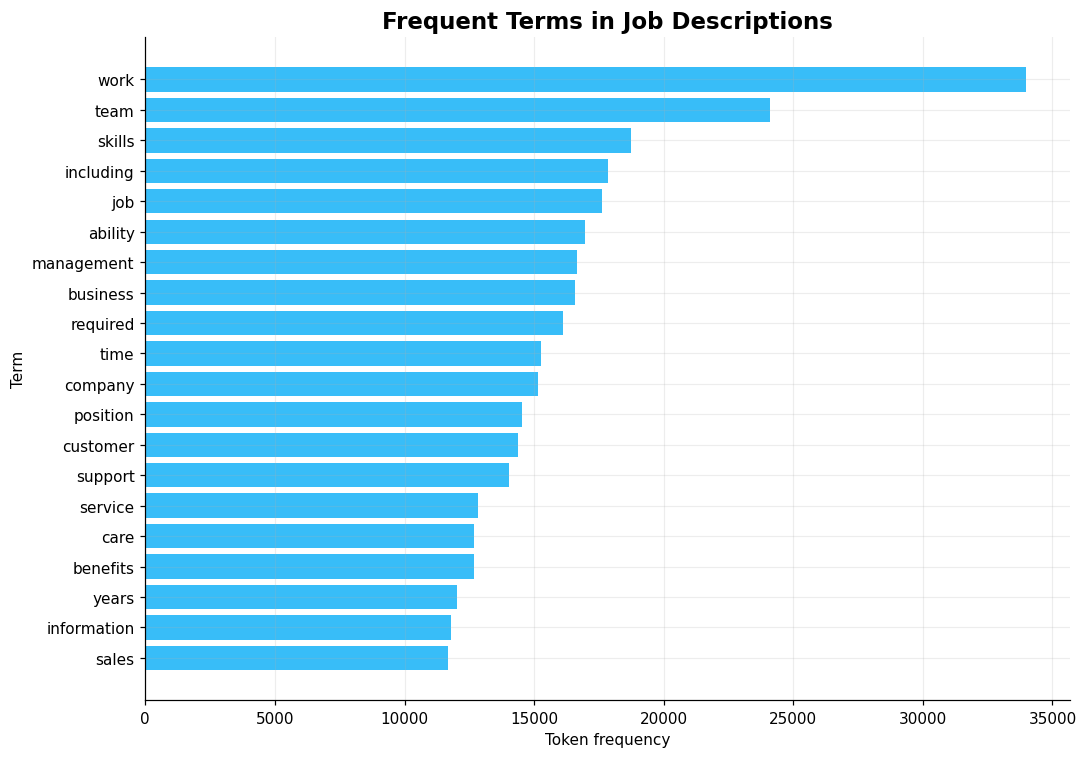

In [51]:
if len(term_freq):
    s=term_freq.head(20).sort_values()
    fig,ax=plt.subplots(figsize=(10,7)); ax.barh(s.index,s.values,color=CYAN)
    ax.set(title="Frequent Terms in Job Descriptions",xlabel="Token frequency",ylabel="Term")
    plt.tight_layout(); plt.show()

## 52. Prepare salary-band classification data

Choose the largest currency/pay-period group and label its salary values using within-group tertiles.

In [52]:
model_data=pd.DataFrame(); model_ready=False
if "salary_midpoint" in jobs and group_cols and "description" in jobs:
    cand=jobs.dropna(subset=["salary_midpoint","description"]+group_cols).copy()
    gs=cand.groupby(group_cols).size().sort_values(ascending=False)
    if len(gs) and gs.iloc[0]>=300:
        chosen_group=gs.index[0]; mask=pd.Series(True,index=cand.index)
        for col,val in zip(group_cols,chosen_group if isinstance(chosen_group,tuple) else (chosen_group,)):
            mask &= cand[col].eq(val)
        model_data=cand.loc[mask,["description","salary_midpoint"]].copy()
        q1,q2=model_data.salary_midpoint.quantile([1/3,2/3])
        model_data["salary_band"]=pd.cut(model_data.salary_midpoint,[-np.inf,q1,q2,np.inf],
            labels=["Lower","Middle","Upper"],include_lowest=True)
        model_data=model_data.dropna(subset=["salary_band"])
        model_ready=len(model_data)>=300 and model_data.salary_band.nunique()>=2
print("Selected group:",chosen_group if "chosen_group" in globals() else "Not available")
print("Rows:",len(model_data),"Ready:",model_ready)

Selected group: ('USD', 'YEARLY')
Rows: 20615 Ready: True


## 53. Train a lightweight text classifier

Fit TF-IDF plus logistic regression to estimate relative salary bands within the selected currency/pay-period group.

In [53]:
if model_ready:
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import Pipeline
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import classification_report,accuracy_score
    Xtr,Xte,ytr,yte=train_test_split(model_data.description,model_data.salary_band.astype(str),
        test_size=.2,random_state=RANDOM_STATE,stratify=model_data.salary_band.astype(str))
    salary_model=Pipeline([("tfidf",TfidfVectorizer(stop_words="english",max_features=10000,
        ngram_range=(1,2),min_df=3,max_df=.9,sublinear_tf=True)),
        ("clf",LogisticRegression(max_iter=400,class_weight="balanced"))])
    salary_model.fit(Xtr,ytr); pred=salary_model.predict(Xte)
    print("Accuracy:",round(accuracy_score(yte,pred),4))
    print(classification_report(yte,pred,zero_division=0))
else: print("Skipped: insufficient observations in one comparable salary group.")

Accuracy: 0.7179
              precision    recall  f1-score   support

       Lower       0.78      0.78      0.78      1374
      Middle       0.62      0.59      0.61      1375
       Upper       0.75      0.78      0.77      1374

    accuracy                           0.72      4123
   macro avg       0.72      0.72      0.72      4123
weighted avg       0.72      0.72      0.72      4123



## 54. Evaluate classifier errors

Visualize the confusion matrix if a model was fitted successfully.

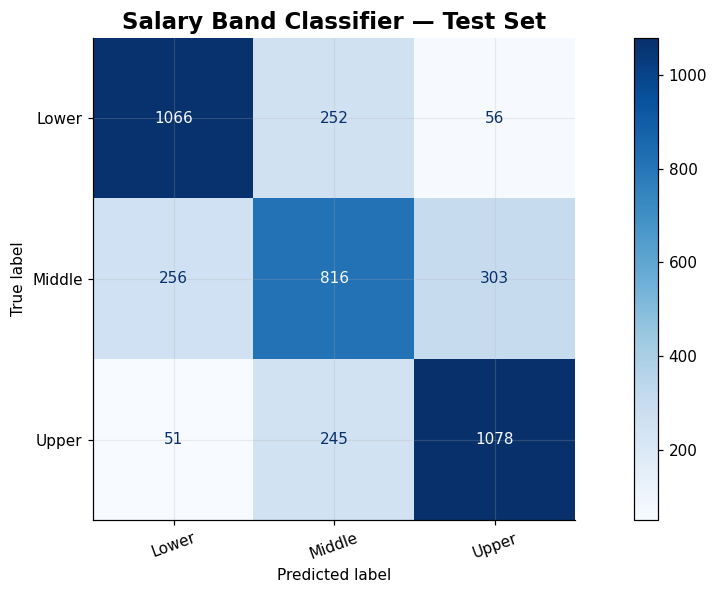

In [54]:
if model_ready and "salary_model" in globals():
    from sklearn.metrics import ConfusionMatrixDisplay
    ConfusionMatrixDisplay.from_predictions(yte,pred,cmap="Blues",values_format="d",xticks_rotation=20)
    plt.title("Salary Band Classifier — Test Set"); plt.tight_layout(); plt.show()
else: print("No fitted classifier to evaluate.")

## 55. Export analysis tables and close

Save reusable outputs and print concise interpretation reminders.

In [55]:
outdir="/kaggle/working" if os.path.isdir("/kaggle/working") else "."
jobs.to_csv(os.path.join(outdir,"linkedin_job_postings_cleaned.csv"),index=False)
if "role_family" in jobs:
    jobs.role_family.value_counts().rename_axis("role_family").reset_index(name="postings").to_csv(
        os.path.join(outdir,"linkedin_role_family_summary.csv"),index=False)
if "salary_midpoint" in jobs:
    cols=[c for c in ["job_id","title","currency","pay_period","salary_midpoint"] if c in jobs]
    jobs[cols].to_csv(os.path.join(outdir,"linkedin_salary_analysis.csv"),index=False)
print("Exports saved to:",outdir)
print("Analysis complete. Keep currencies and pay periods separate; interpret this scraped sample cautiously.")

Exports saved to: /kaggle/working
Analysis complete. Keep currencies and pay periods separate; interpret this scraped sample cautiously.



<div style="padding:26px;border-radius:18px;background:linear-gradient(125deg,#071426,#102d46,#155e75);color:#f8fafc;border:1px solid #38bdf8;">
<h2 style="color:#67e8f9;">Final Takeaways</h2>
<p>This notebook examines job demand, work arrangements, experience levels, locations, compensation metadata, employers, skills, benefits, and language used in job descriptions.</p>
<p>Interpret findings as exploratory evidence. Scraped listings may be incomplete or unevenly represented. Salary comparisons are especially sensitive to missingness, currency, and pay period. The text classifier is a baseline experiment, not a production compensation system.</p>
<hr style="border-color:#38bdf8;">
<p><b>Dataset:</b> LinkedIn Job Postings — 2023–2024, by Arshkon, with additional postings credited to Zoey Yuzou.</p>
<p><b>Scraper:</b> <a href="https://github.com/ArshKA/LinkedIn-Job-Scraper" style="color:#67e8f9;">GitHub repository</a></p>
<p><b>Created by:</b> Mobeen Fatima · Kaggle: @mobeenfatimah</p>
</div>
